#PROYECTO INTEGRADOR GRUPO 6
#TÍTULO DEL PROYECTO

Integrantes:

*   Juan Carlos Fonseca Florez
*   Zarith Dorelly Gómez Vargas
*   Erika Fernanda Jiménez Camargo


#PROCESAMIENTO

## 1.Importación de Librerías y Carga de Datos

In [ ]:
#Importar Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

pd.set_option('display.max_columns', None)

# Cargar datos

df = pd.read_csv('Datos_Preprocesamiento.csv')

# Dimensiones
print(df.shape)

# Primeras filas
print(df.head())

(110595, 18)
                   Compania                   Liquidador  Evento  \
0             REALE SEGUROS  Liquidador Interno Compañia  NORMAL   
1  RENTA NACIONAL GENERALES    CHARLES TAYLOR CHILE S.A.  NORMAL   
2  RENTA NACIONAL GENERALES    CHARLES TAYLOR CHILE S.A.  NORMAL   
3  RENTA NACIONAL GENERALES    CHARLES TAYLOR CHILE S.A.  NORMAL   
4             REALE SEGUROS  Liquidador Interno Compañia  NORMAL   

  Fecha_Aviso_Corredora Fecha_Plazo_Cierre               Nombre_Ramo Canal  \
0            2026-04-29         2026-06-28  Vehic. Motoriz. Livianos   DIR   
1            2026-03-12         2026-05-11                  Incendio   DIR   
2            2026-03-10         2026-05-09                  Incendio   DIR   
3            2026-03-05         2026-05-04                  Incendio   DIR   
4            2026-04-29         2026-06-28  Vehic. Motoriz. Livianos   DIR   

          Ciudad_y          Director_Comercial  Total_Prima_Bruta_Moneda  \
0         Santiago          RISOP

In [ ]:
# Carga de Datos de EMBI (variable Riesgo país a agregar)
try:
    EMBI = pd.read_excel('serie_Historica.xlsx')
    EMBI = EMBI[['Fecha', 'Chile']]
    print("Datos cargados exitosamente:")
    print(EMBI.info())
except FileNotFoundError:
    print("Error: El archivo 'libro de producción_tokenizado2.parquet' no fue encontrado. Por favor, verifica la ruta y el nombre del archivo.")
except Exception as e:
    print(f"Ocurrió un error al cargar el archivo: {e}")


Datos cargados exitosamente:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4627 entries, 0 to 4626
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Fecha   4627 non-null   datetime64[ns]
 1   Chile   4627 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 72.4 KB
None


In [ ]:
# Carga de Datos de Inflación (variable a agregar)
try:
    Inflacion = pd.read_excel('inflacion_variacion_anual_ipc_chile.xlsx')
    print("Datos cargados exitosamente:")
    print(Inflacion.info())
except FileNotFoundError:
    print("Error: El archivo 'libro de producción_tokenizado2.parquet' no fue encontrado. Por favor, verifica la ruta y el nombre del archivo.")
except Exception as e:
    print(f"Ocurrió un error al cargar el archivo: {e}")

Datos cargados exitosamente:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   fecha      28 non-null     datetime64[ns]
 1   inflación  28 non-null     float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 580.0 bytes
None


##2.Revisión Previa

In [ ]:
#Revisión Tipo de Datos
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110595 entries, 0 to 110594
Data columns (total 18 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Compania                  109157 non-null  object 
 1   Liquidador                110595 non-null  object 
 2   Evento                    109155 non-null  object 
 3   Fecha_Aviso_Corredora     109155 non-null  object 
 4   Fecha_Plazo_Cierre        110595 non-null  object 
 5   Nombre_Ramo               109155 non-null  object 
 6   Canal                     110595 non-null  object 
 7   Ciudad_y                  110595 non-null  object 
 8   Director_Comercial        110595 non-null  object 
 9   Total_Prima_Bruta_Moneda  110595 non-null  float64
 10  Total_Prima_Bruta_Peso    110595 non-null  float64
 11  Prima_Neta                110595 non-null  float64
 12  Valor_Cuota               110595 non-null  float64
 13  NO_Renovada               110595 non-null  b

In [ ]:
#Revisión Valores Nulos

nulos = df.isnull().sum().sort_values(ascending=False)
print(nulos)

Fecha_Aviso_Corredora       1440
Evento                      1440
Nombre_Ramo                 1440
Compania                    1438
Liquidador                     0
Fecha_Plazo_Cierre             0
Canal                          0
Ciudad_y                       0
Director_Comercial             0
Total_Prima_Bruta_Moneda       0
Total_Prima_Bruta_Peso         0
Prima_Neta                     0
Valor_Cuota                    0
NO_Renovada                    0
Sin_Plan_Pago                  0
Linea_Negocio                  0
Sucursal                       0
Garantia_Suscripcion           0
dtype: int64


In [ ]:
#Revisisón Duplicados
duplicados = df.duplicated().sum()

print(f'Número de registros duplicados: {duplicados}')

Número de registros duplicados: 40369


In [ ]:
#Resumen Estadístico
print(df.describe())

       Total_Prima_Bruta_Moneda  Total_Prima_Bruta_Peso    Prima_Neta  \
count              1.105950e+05            1.105950e+05  1.105950e+05   
mean               4.591243e+02            3.309711e+06  4.012271e+02   
std                1.121584e+04            2.768176e+08  1.000518e+04   
min               -6.397137e+04           -5.687267e+08 -6.219870e+04   
25%               -2.665000e+00            0.000000e+00 -2.363100e+00   
50%                3.642000e+00            0.000000e+00  8.340000e+00   
75%                3.690850e+01            0.000000e+00  3.288560e+01   
max                2.372741e+06            9.115286e+10  1.993900e+06   

         Valor_Cuota  
count  110595.000000  
mean       22.385123  
std       976.559576  
min     -4480.888800  
25%         0.000000  
50%         0.000000  
75%         0.000000  
max    137229.750000  


##3.Inclusión de Variables Riesgo País e Inflación

In [ ]:
EMBI = EMBI.drop_duplicates(subset='Fecha')

In [ ]:
# Asegurar datetime
df['Fecha_Aviso_Corredora'] = pd.to_datetime(df['Fecha_Aviso_Corredora'])
EMBI['Fecha'] = pd.to_datetime(EMBI['Fecha'])

# Quitar nulos (del error anterior)
df = df.dropna(subset=['Fecha_Aviso_Corredora'])

# Ordenar (CLAVE)
df = df.sort_values('Fecha_Aviso_Corredora')
EMBI = EMBI.sort_values('Fecha')

# Merge correcto
df_final = pd.merge_asof(
    df,
    EMBI,
    left_on='Fecha_Aviso_Corredora',
    right_on='Fecha',
    direction='backward'
)

df_final = df_final.rename(columns={'Chile': 'Riesgo_Pais'})
df_final = df_final.drop(columns=['Fecha'])

In [ ]:
df_final['Fecha_Aviso_Corredora'] = pd.to_datetime(df_final['Fecha_Aviso_Corredora'])
Inflacion['fecha'] = pd.to_datetime(Inflacion['fecha'])

df_final = df_final.sort_values('Fecha_Aviso_Corredora')
Inflacion = Inflacion.sort_values('fecha')

df_final = pd.merge_asof(
    df_final,
    Inflacion,
    left_on='Fecha_Aviso_Corredora',
    right_on='fecha',
    direction='backward'
)

df_final = df_final.rename(columns={'inflación': 'Inflacion'})
df_final = df_final.drop(columns=['fecha'])

In [ ]:
df_final.head(20)

,Compania,Liquidador,Evento,Fecha_Aviso_Corredora,Fecha_Plazo_Cierre,Nombre_Ramo,Canal,Ciudad_y,Director_Comercial,Total_Prima_Bruta_Moneda,Total_Prima_Bruta_Peso,Prima_Neta,Valor_Cuota,NO_Renovada,Sin_Plan_Pago,Linea_Negocio,Sucursal,Garantia_Suscripcion,Riesgo_Pais,Inflacion
0,FID,FERNANDO ANTONIO JARA PEREZ,NORMAL,2025-01-01,2026-02-18,Vehic- Motoriz. Pesados,IMP,Viña Del Mar,"SOUSA LACAMARA, Gonzalo",116.204,0.0,97.65,0.0,False,False,Old Gallagher,AJG Viña del Mar,False,1.17114,0.049
1,FID,FERNANDO ANTONIO JARA PEREZ,NORMAL,2025-01-01,2026-02-18,Vehic- Motoriz. Pesados,IMP,Viña Del Mar,"SOUSA LACAMARA, Gonzalo",-19.135,0.0,-16.08,0.0,False,False,Old Gallagher,AJG Viña del Mar,False,1.17114,0.049
2,FID,FERNANDO ANTONIO JARA PEREZ,NORMAL,2025-01-01,2026-02-18,Vehic- Motoriz. Pesados,IMP,Viña Del Mar,"SOUSA LACAMARA, Gonzalo",10.793,0.0,9.07,0.0,False,False,Old Gallagher,AJG Viña del Mar,False,1.17114,0.049
3,FID,FERNANDO ANTONIO JARA PEREZ,NORMAL,2025-01-01,2026-02-18,Vehic- Motoriz. Pesados,IMP,Viña Del Mar,"SOUSA LACAMARA, Gonzalo",40.662,0.0,34.17,0.0,False,False,Old Gallagher,AJG Viña del Mar,False,1.17114,0.049
4,FID,FERNANDO ANTONIO JARA PEREZ,NORMAL,2025-01-01,2026-02-18,Vehic- Motoriz. Pesados,IMP,Viña Del Mar,"SOUSA LACAMARA, Gonzalo",96.366,0.0,80.98,0.0,False,False,Old Gallagher,AJG Viña del Mar,False,1.17114,0.049
5,FID,FERNANDO ANTONIO JARA PEREZ,NORMAL,2025-01-01,2026-02-18,Vehic- Motoriz. Pesados,IMP,Viña Del Mar,"SOUSA LACAMARA, Gonzalo",718.868,0.0,604.09,0.0,False,False,Old Gallagher,AJG Viña del Mar,False,1.17114,0.049
6,FID,FERNANDO ANTONIO JARA PEREZ,NORMAL,2025-01-01,2026-02-18,Vehic- Motoriz. Pesados,IMP,Viña Del Mar,"SOUSA LACAMARA, Gonzalo",15.541,0.0,13.06,0.0,False,False,Old Gallagher,AJG Viña del Mar,False,1.17114,0.049
7,FID,FERNANDO ANTONIO JARA PEREZ,NORMAL,2025-01-01,2026-02-18,Vehic- Motoriz. Pesados,IMP,Viña Del Mar,"SOUSA LACAMARA, Gonzalo",18.838,0.0,15.83,0.0,False,False,Old Gallagher,AJG Viña del Mar,False,1.17114,0.049
8,FID,FERNANDO ANTONIO JARA PEREZ,NORMAL,2025-01-01,2026-02-18,Vehic- Motoriz. Pesados,IMP,Viña Del Mar,"SOUSA LACAMARA, Gonzalo",0.000,0.0,8.34,0.0,False,False,Old Gallagher,AJG Viña del Mar,False,1.17114,0.049
9,FID,FERNANDO ANTONIO JARA PEREZ,NORMAL,2025-01-01,2026-02-18,Vehic- Motoriz. Pesados,IMP,Viña Del Mar,"SOUSA LACAMARA, Gonzalo",283.100,0.0,237.90,0.0,False,False,Old Gallagher,AJG Viña del Mar,False,1.17114,0.049


In [ ]:
mapping = {
    'Vehic- Motoriz. Pesados': 'cola corta',
    'Vehic. Motoriz. Livianos': 'cola corta',
    'Todo Riesgo Bs. Fisicos': 'cola corta',
    'R. Civil Profesional': 'cola larga',
    'Incendio': 'cola corta',
    'Accidentes Personales Generales': 'cola corta',
    'R. Civil General': 'cola larga',
    'Stock Throughput': 'cola corta',
    'Todo Riesgo Construcción y Montaje': 'cola larga',
    'Cabotaje Terrestre': 'cola corta',
    'Equipo Movil': 'cola corta',
    'Fidelidad Funcionaria': 'cola larga',
    'Transp. Internacional': 'cola corta',
    'Transporte Terrestre': 'cola corta',
    'Transp. Intern. Maritimo': 'cola corta',
    'Instal. Electronicas': 'cola corta',
    'Casco Marítimo': 'cola corta',
    'Robo Con Fractura': 'cola corta',
    'Miscelaneo': 'cola corta',
    'Remesa De Valores': 'cola corta',
    'Cabotaje Maritimo': 'cola corta',
    'Transp. Terrestre Nacional': 'cola corta',
    'R. Civil Directores Y Administ.': 'cola larga',
    'Vida Comunidades': 'cola larga',
    'R. Civil En Exceso': 'cola larga',
    'Equipo Electrónico': 'cola corta',
    'Transporte Maritimo': 'cola corta',
    'Transp. Intern. Terrestre': 'cola corta',
    'Todo Riesgo Objetos Valiosos': 'cola corta',
    'Casco Aereo': 'cola corta',
    'Equipo Agricola': 'cola corta',
    'Otros Seguros': 'depende del ramo',
    'R. Civil Internacional': 'cola larga',
    'Accidentes Personales': 'cola larga',
    'R. Civil En Exceso Veh': 'cola larga'
}

df_final['etiqueta'] = df_final['Nombre_Ramo'].map(mapping)

print(df_final['etiqueta'].value_counts())


etiqueta
cola corta          103154
cola larga            6000
depende del ramo         1
Name: count, dtype: int64


In [ ]:
columnas_numericas = df.select_dtypes(include='number').columns

print(columnas_numericas)

Index(['Total_Prima_Bruta_Moneda', 'Total_Prima_Bruta_Peso', 'Prima_Neta',
       'Valor_Cuota'],
      dtype='object')


In [ ]:
df_final = df_final.drop_duplicates()

In [ ]:
df_final.to_csv('Datos_Final.csv', index=False)

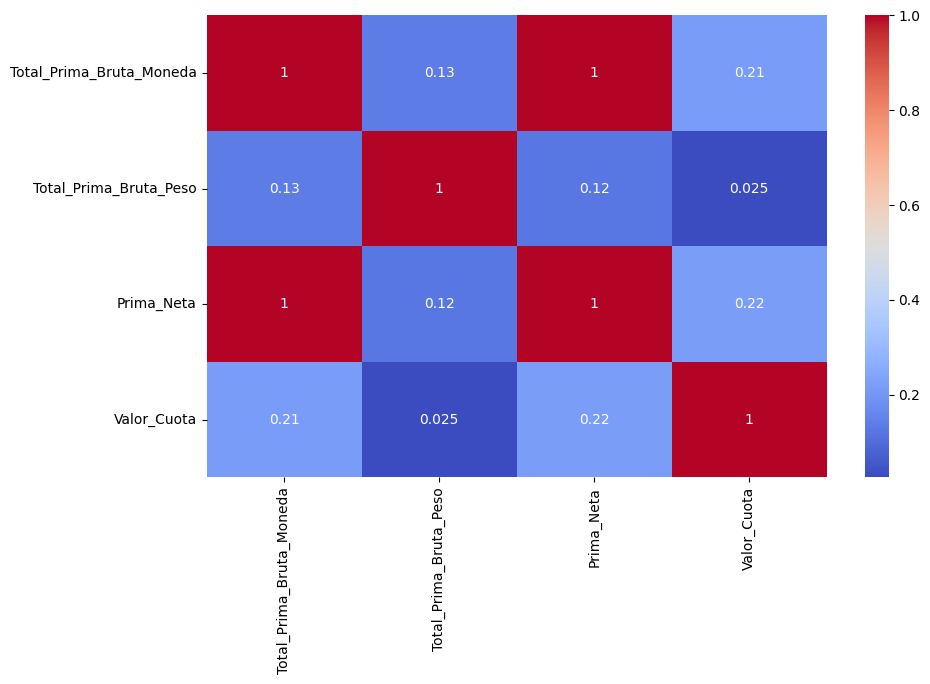

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df_final[columnas_numericas].corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

In [ ]:
#Correlación entre Variables Numéricas
plt.figure(figsize=(10,6))

corr = df[numericas].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Matriz de correlación')
plt.show()

In [ ]:
columnas_categoricas = [
    'Compania',
    'Liquidador',
    'Evento',
    'Nombre_Ramo',
    'Canal',
    'Ciudad_y',
    'Director_Comercial',
    'Linea_Negocio',
    'Sucursal',
    'etiqueta'
]

In [ ]:
for col in columnas_categoricas:
    print(f"\n{col}")
    print(df[col].nunique())

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# =========================
# BOOLEANOS
# =========================

columnas_booleanas = [
    'NO_Renovada',
    'Sin_Plan_Pago',
    'Garantia_Suscripcion'
]

for col in columnas_booleanas:
    df[col] = df[col].fillna(False).astype(int)

# =========================
# CATEGORICAS
# =========================

columnas_categoricas = [
    'Compania',
    'Liquidador',
    'Evento',
    'Nombre_Ramo',
    'Canal',
    'Ciudad_y',
    'Director_Comercial',
    'Linea_Negocio',
    'Sucursal',
    'etiqueta'
]

# Opción 1: Label Encoding
le = LabelEncoder()

for col in columnas_categoricas:
    # Fill NaN values in categorical columns before encoding if any remain
    # For LabelEncoder, it's often best to ensure no NaNs or handle them specifically
    # For now, assuming no NaNs after boolean handling, but adding a fillna for robustness
    df[col] = df[col].fillna('Missing').astype(str) # Fill with a placeholder string and ensure string type
    df[col] = le.fit_transform(df[col])

print(df.info())

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Suponiendo que tienes un DataFrame llamado 'data' que contiene tus datos
# Puedes calcular la matriz de correlación de esta manera:
correlation_matrix = df.corr(numeric_only=True)

# Puedes visualizar la matriz de correlación utilizando seaborn
plt.figure(figsize=(16, 13))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlación')
plt.show()

In [ ]:
# Matriz de correlación
correlation_matrix = df.corr(numeric_only=True)

# Correlación con la variable objetivo
corr_target = correlation_matrix['NO_Renovada']

# Ordenar de mayor a menor correlación absoluta
corr_target = corr_target.reindex(
    corr_target.abs().sort_values(ascending=False).index
)

# Mostrar resultados
print(corr_target)

NO_Renovada
False    110455
True        140
Name: count, dtype: int64
NO_Renovada
False    0.998734
True     0.001266
Name: proportion, dtype: float64


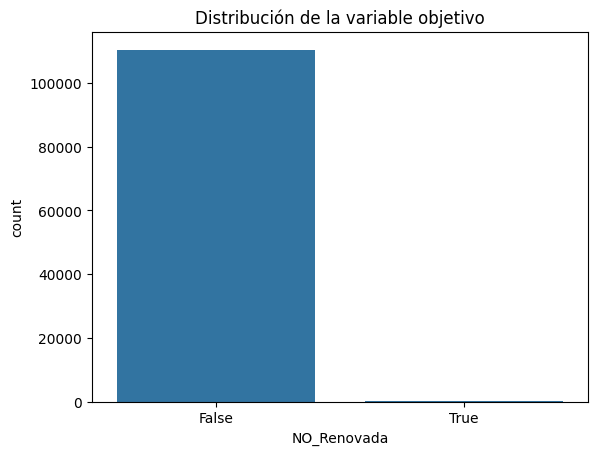

In [ ]:
#Distribución de variable ojetivo NO_Renovada
print(df['NO_Renovada'].value_counts())
print(df['NO_Renovada'].value_counts(normalize=True))

sns.countplot(x='NO_Renovada', data=df)
plt.title('Distribución de la variable objetivo')
plt.show()